# Analiza cantitativă a piețelor de energie — Cursul 1: Piețele de energie și datele lor
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București; Academia Română, Institutul de Prognoză Economică

Acest notebook Jupyter reproduce numerele și graficele din Cursul 1 pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Încercați singuri* de pe slide-uri.

**Reguli folosite peste tot:** datele se opresc la ultima lună completă; valorile lipsă rămîn lipsă (nu le interpolăm și nu le socotim zero); prețurile negative se numără în echivalent-ore (un interval de 15 minute contează 0,25 h).

## §1 Date, ceasuri și data-limită

In [ ]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/notebooks')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings('ignore')

DATA = '../data/clean/'
P = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
X.index = X.index.tz_convert('Europe/Brussels')          # CET/CEST delivery-day clock
H = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
H.index = H.index.tz_convert('Europe/Brussels')
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
G = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
BGH = pd.read_csv(DATA + 'generation_bg_mw_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
CB = pd.read_csv(DATA + 'crossborder_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
F = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')
TTF = pd.read_csv(DATA + 'ttf_monthly.csv'); TTF.index = pd.PeriodIndex(TTF['month'], freq='M').to_timestamp()

# cut-off: last complete month common to prices and generation
raw_last = min(P['RO'].dropna().index.max(), G['hydro_run_of_river'].dropna().index.max())
END = (raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
Y = END.year
end_utc = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')
P, G, CB, F = P.loc[:END], G.loc[:END], CB.loc[:END], F.loc[:END]
X, H = X.loc[:str(END.date())], H.loc[:str(END.date())]
GH, BGH = GH[GH.index < end_utc], BGH[BGH.index < end_utc]
PF = P.asfreq('D')   # full calendar: a change across a gap stays missing
print('cut-off:', END.date(), '| 60-min MTUs:', (X['mtu_minutes'] == 60).sum(), '| 15-min MTUs:', (X['mtu_minutes'] == 15).sum())

cut-off: 2026-10-31 | 60-min MTUs: 94222 | 15-min MTUs: 38020


In [2]:
# missing days in the daily price series (left missing, never filled)
for z in ['RO', 'BG']:
    s = PF[z].loc[PF[z].first_valid_index():]
    print(z, 'first day', s.index.min().date(), '| missing days:', int(s.isna().sum()), [d.date() for d in s[s.isna()].index][:6])

RO first day 2015-01-01 | missing days: 5 [datetime.date(2015, 9, 21), datetime.date(2015, 12, 20), datetime.date(2015, 12, 21), datetime.date(2017, 12, 31), datetime.date(2018, 8, 17)]
BG first day 2016-10-31 | missing days: 15 [datetime.date(2016, 11, 15), datetime.date(2016, 11, 18), datetime.date(2016, 11, 19), datetime.date(2016, 11, 27), datetime.date(2016, 11, 30), datetime.date(2016, 12, 3)]


Q45 12:00-12:15 RO (EEST) / 11:00-11:15 CET | price 152.23 | MW offered at <= 0: 2332.6 | net import MW: -48.3
Q77 20:00-20:15 RO (EEST) / 19:00-19:15 CET | price 244.0 | MW offered at <= 0: 3032.9 | net import MW: 1054.0


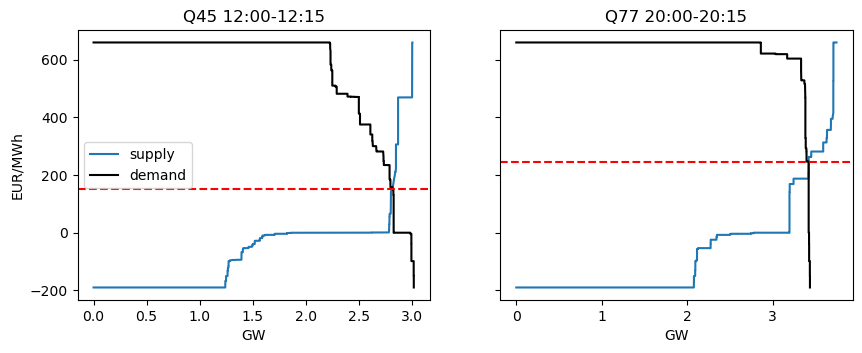

In [3]:
# merit order on the real OPCOM aggregated curves (one day, two quarter-hours)
import json
CU = pd.read_csv(DATA + 'opcom_pzu_curves.csv'); META = json.load(open(DATA + 'opcom_pzu_curves_meta.json'))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, iv in zip(axs, META['intervals']):
    for side, col in [('supply', 'tab:blue'), ('demand', 'black')]:
        c = CU[(CU['interval'] == iv['interval_label']) & (CU['side'] == side)]
        ax.plot(c['quantity_mw'] / 1000, c['price_eur_mwh'].clip(-190, 660), color=col, label=side)
    ax.axhline(iv['official_clearing_price_eur_mwh'], color='red', ls='--')
    s = CU[(CU['interval'] == iv['interval_label']) & (CU['side'] == 'supply')]
    print(iv['interval_label'], '| price', iv['official_clearing_price_eur_mwh'], '| MW offered at <= 0:',
          s.loc[s['price_eur_mwh'] <= 0, 'quantity_mw'].max(), '| net import MW:', -iv['net_export_mw'])
    ax.set_title(iv['interval_label'][:15]); ax.set_xlabel('GW')
axs[0].set_ylabel('EUR/MWh'); axs[0].legend(); plt.show()

2026-10-28 | energy MWh: 159558 | mean MW: 6648 | min/max MW: 5253 7719


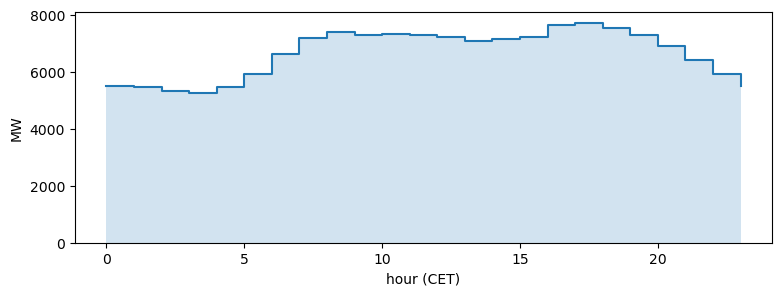

In [4]:
# one day of Romanian load: power (MW) and energy (MWh = area under the curve)
ld = GH['load'].tz_convert('Europe/Brussels')
cnt = ld.groupby(ld.index.date).count()
day = max(k for k, v in cnt.items() if v == 24 and pd.Timestamp(k).dayofweek == 2)
one = ld[ld.index.date == day]
print(day, '| energy MWh:', round(one.sum()), '| mean MW:', round(one.mean()), '| min/max MW:', round(one.min()), round(one.max()))
plt.figure(figsize=(9, 3)); plt.step(range(24), one.values, where='post'); plt.fill_between(range(24), one.values, step='post', alpha=0.2)
plt.ylabel('MW'); plt.xlabel('hour (CET)'); plt.ylim(0); plt.show()

## §2 Mixul de producție al României (energie din orele raportate, cu acoperire)

               Hydro  Coal  Nuclear   Gas  Wind  Solar  Biomass
timestamp_utc                                                  
2015            26.2  28.3     17.9  14.6  10.3    1.9      0.8
2016            28.6  25.3     17.7  15.6  10.1    2.0      0.7
2017            23.1  27.3     18.3  17.0  11.6    2.2      0.7
2018            27.9  24.9     17.9  16.8   9.8    2.1      0.6
2019            26.8  23.6     19.2  15.9  11.4    2.3      0.7
2020            27.8  17.4     20.7  18.4  12.4    2.4      0.9
2021            29.6  18.6     19.2  18.2  11.1    2.2      1.0
2022            25.5  19.1     20.1  19.2  12.5    2.5      1.0
2023            32.4  14.4     19.8  16.9  13.2    2.6      0.7
2024            27.9  13.6     21.1  20.1  12.4    4.1      0.9
2025            25.6  13.8     21.3  20.2  12.4    5.7      0.9
minimum coverage in full years: 98.1%


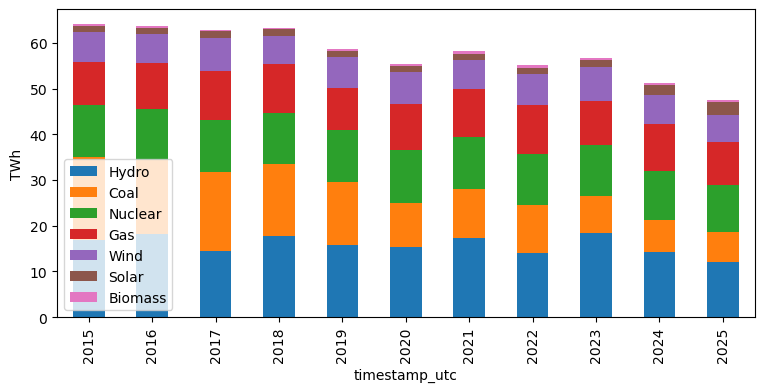

In [5]:
GRP = {'Hydro': ['hydro_run_of_river', 'hydro_water_reservoir'], 'Coal': ['brown_coal_lignite', 'hard_coal'],
       'Nuclear': ['nuclear'], 'Gas': ['gas'], 'Wind': ['wind_onshore'], 'Solar': ['solar'], 'Biomass': ['biomass']}
yr = GH.index.year
mix = pd.DataFrame({k: GH[c].sum(axis=1, min_count=len(c)).groupby(yr).sum() / 1e6 for k, c in GRP.items()})   # TWh
cov = pd.DataFrame({k: GH[c].sum(axis=1, min_count=len(c)).notna().groupby(yr).mean() for k, c in GRP.items()})
full = [y for y in mix.index if y < Y]
share = mix.div(mix.sum(axis=1), axis=0) * 100
print(share.loc[full].round(1))
print('minimum coverage in full years: %.1f%%' % (cov.loc[full].min().min() * 100))
mix.loc[full].plot(kind='bar', stacked=True, figsize=(9, 4), ylabel='TWh'); plt.show()

In [6]:
# like-for-like: Jan..cut-off month of this year vs last year, hours reported in BOTH years
def lfl(cols):
    s = GH[cols].sum(axis=1, min_count=len(cols))
    a = s[(s.index.year == Y) & (s.index.month <= END.month)]
    b = s[(s.index.year == Y - 1) & (s.index.month <= END.month)]
    A = pd.Series(a.values, index=a.index.strftime('%m-%d %H')); A = A[~A.index.duplicated()]
    B = pd.Series(b.values, index=b.index.strftime('%m-%d %H')); B = B[~B.index.duplicated()]
    j = pd.concat([A.rename('now'), B.rename('before')], axis=1)
    both = j.dropna()
    return pd.Series({'TWh now': both['now'].sum() / 1e6, 'TWh before': both['before'].sum() / 1e6,
                      'change %': (both['now'].sum() / both['before'].sum() - 1) * 100, 'coverage %': len(both) / len(j) * 100})
print(pd.DataFrame({k: lfl(c) for k, c in GRP.items()}).T.round(2))

         TWh now  TWh before  change %  coverage %
Hydro      10.44        9.61      8.60       99.97
Coal        4.58        5.40    -15.22       99.99
Nuclear     5.10        7.42    -31.27       90.09
Gas         7.77        7.40      5.07       99.99
Wind        5.27        4.70     12.22       99.97
Solar       4.33        2.53     71.19       99.97
Biomass     0.38        0.34     11.51       99.99


## §3 Nivelul prețurilor și sezonalitatea

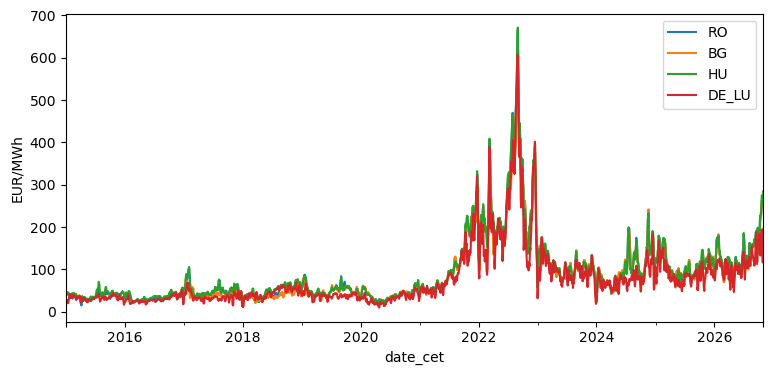

mean by year
              RO     BG     HU  DE_LU
date_cet                            
2018       46.4   39.9   51.0   44.5
2019       50.4   47.5   50.4   37.7
2020       39.5   39.3   39.0   30.5
2021      111.4  108.7  113.8   96.8
2022      265.3  252.8  271.7  235.5
2023      103.7  103.8  106.8   95.2
2024      103.5  102.5  100.8   78.5
2025      108.2  106.9  108.5   89.3
2026      137.4  129.9  141.0  114.0 
sd of daily changes
             RO    BG    HU  DE_LU
date_cet                         
2018      10.9  13.6   9.2   11.5
2019      11.5  12.8   9.2   11.9
2020       8.6   9.8   8.5   11.5
2021      25.2  23.6  24.8   34.4
2022      58.9  56.6  56.6   65.3
2023      26.3  26.2  25.0   30.3
2024      32.4  31.5  34.7   31.4
2025      24.4  23.9  25.3   28.3
2026      31.6  28.2  32.6   36.0


In [7]:
Z = ['RO', 'BG', 'HU', 'DE_LU']
P[Z].rolling(7).mean().plot(figsize=(9, 4), ylabel='EUR/MWh'); plt.show()
byyear = pd.DataFrame({z: P[z].groupby(P.index.year).mean() for z in Z}).round(1)
vol = pd.DataFrame({z: PF[z].diff().groupby(PF.index.year).std() for z in Z}).round(1)
print('mean by year\n', byyear.loc[2018:], '\nsd of daily changes\n', vol.loc[2018:])

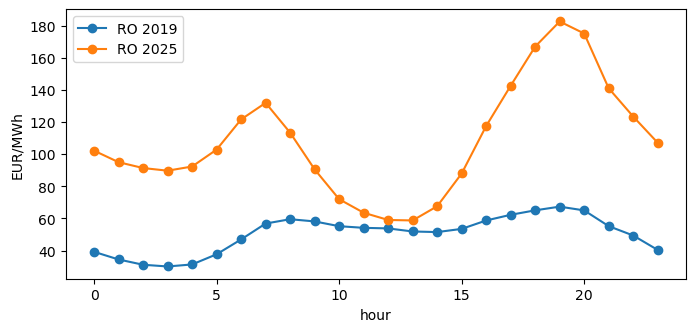

            RO  DE_LU
date_cet             
0          9.1    7.0
1         12.7   11.0
2         12.6   11.6
3         10.4    7.9
4          3.4    3.3
5        -17.5  -15.8
6        -30.7  -25.1


In [8]:
hh = H.copy(); hh['hour'] = hh.index.hour
prof = pd.DataFrame({f'RO {y}': hh.loc[str(y)].groupby('hour')['RO'].mean() for y in [2019, 2025]})
prof.plot(marker='o', figsize=(8, 3.5), ylabel='EUR/MWh'); plt.show()
# weekly pattern: distance of each weekday from the mean of its own ISO week
wk = P.loc['2023-01-01':, ['RO', 'DE_LU']].dropna()
iso = wk.index.isocalendar(); key = iso['year'].astype(str) + '-' + iso['week'].astype(str)
full_w = (key.map(key.value_counts()) == 7).values
wk, key = wk[full_w], key[full_w]
print((wk - wk.groupby(key.values).transform('mean')).groupby(wk.index.dayofweek).mean().round(1))

## §4 Vîrfuri și prețuri negative (echivalent-ore)

In [9]:
hrs = X['mtu_minutes'] / 60
neg_h = pd.DataFrame({z: ((X[z] < 0) & X[z].notna()).mul(hrs).groupby(X.index.year).sum() for z in Z})
neg_n = pd.DataFrame({z: ((X[z] < 0) & X[z].notna()).groupby(X.index.year).sum() for z in Z})
print('hour-equivalents\n', neg_h.loc[2022:], '\nnumber of negative MTUs\n', neg_n.loc[2022:])

def wquantile(x, w, q):
    o = np.argsort(x); x, w = np.asarray(x)[o], np.asarray(w)[o]
    return float(np.interp(q, (np.cumsum(w) - 0.5 * w) / w.sum(), x))

s = X[['RO', 'mtu_minutes']].dropna()
for y, g in s.groupby(s.index.year):
    w = g['mtu_minutes'].values / 60
    q1, q3 = wquantile(g['RO'].values, w, 0.25), wquantile(g['RO'].values, w, 0.75)
    thr = q3 + 3 * (q3 - q1)
    print(y, 'threshold %.0f EUR/MWh, spike hours %.2f' % (thr, ((g['RO'] > thr) * w).sum()))

hour-equivalents
                    RO      BG     HU   DE_LU
timestamp_utc                               
2022             0.00    0.00    0.0   69.00
2023            32.00   11.00   74.0  301.00
2024            85.00   55.00  262.0  457.00
2025           196.00  170.00  281.0  574.75
2026           171.75  152.25  223.5  465.00 
number of negative MTUs
                 RO   BG   HU  DE_LU
timestamp_utc                      
2022             0    0    0     69
2023            32   11   74    301
2024            85   55  262    457
2025           196  170  281    724
2026           687  609  894   1860
2015 threshold 106 EUR/MWh, spike hours 0.00
2016 threshold 92 EUR/MWh, spike hours 0.00
2017 threshold 143 EUR/MWh, spike hours 15.00
2018 threshold 146 EUR/MWh, spike hours 0.00
2019 threshold 134 EUR/MWh, spike hours 47.00
2020 threshold 109 EUR/MWh, spike hours 54.00
2021 threshold 394 EUR/MWh, spike hours 69.00
2022 threshold 873 EUR/MWh, spike hours 4.00
2023 threshold 292 EUR/MWh

## §5 Transformări, cozi groase, volatilitate în grupuri

share <= 0: 4.07% | skew 1.19 -> 0.13 | excess kurtosis 6.73 -> -0.55
Brent: excess kurtosis 13.98, JB 23500
Ljung-Box(10): returns 28.1, squared returns 506.9


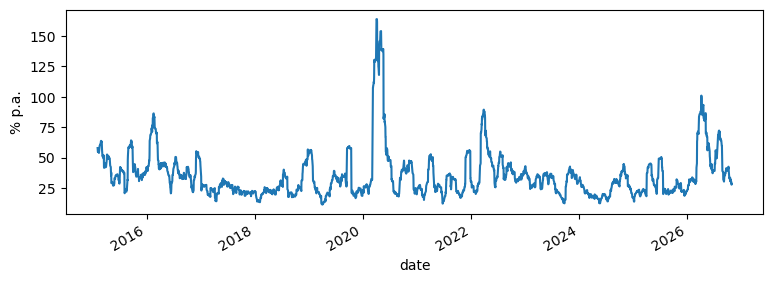

In [10]:
y = X.loc[str(Y), 'RO'].dropna()   # all 15-min prices of the current year
med, mad = y.median(), stats.median_abs_deviation(y, scale='normal')
z = np.arcsinh((y - med) / mad)
print('share <= 0: %.2f%%' % ((y <= 0).mean() * 100), '| skew %.2f -> %.2f' % (stats.skew(y), stats.skew(z)),
      '| excess kurtosis %.2f -> %.2f' % (stats.kurtosis(y), stats.kurtosis(z)))
b = F['brent_usd_bbl'].dropna()
# the continuous front-month switches contract on the first trading day of each month: drop those days
ROLL = b.groupby(b.index.to_period('M')).head(1).index
r = np.log(b).diff().dropna() * 100; r = r.drop(r.index.intersection(ROLL))
print('Brent: excess kurtosis %.2f, JB %.0f' % (stats.kurtosis(r), stats.jarque_bera(r).statistic))
print('Ljung-Box(10): returns %.1f, squared returns %.1f' % (acorr_ljungbox(r, lags=[10])['lb_stat'].iloc[0],
                                                          acorr_ljungbox(r ** 2, lags=[10])['lb_stat'].iloc[0]))
(r.rolling(21).std() * np.sqrt(252)).plot(figsize=(9, 3), ylabel='% p.a.'); plt.show()

## §6 Staționaritate, autocorelație și reperul naiv
Singurele serii simulate din curs (zgomot alb, AR(1), mers aleator) sînt generate aici, doar pentru a ilustra conceptul.

In [11]:
rng = np.random.default_rng(20261104); e = rng.standard_normal(500)
ar = np.zeros(500)
for t in range(1, 500):
    ar[t] = 0.9 * ar[t - 1] + e[t]
for name, s in [('white noise', e), ('AR(1)', ar), ('random walk', np.cumsum(e))]:
    print(name, 'ACF lag 1 = %.2f, lag 10 = %.2f' % tuple(acf(s, nlags=10, fft=True)[[1, 10]]))
sA = P['RO'].loc['2023-01-01':].dropna()
print('RO daily price: ACF(1) %.3f, ACF(7) %.3f, PACF(7) %.3f' % (acf(sA, nlags=7, fft=True)[1], acf(sA, nlags=7, fft=True)[7],
                                                            pacf(sA, nlags=7, method='ywm')[7]))

white noise ACF lag 1 = -0.03, lag 10 = 0.07
AR(1) ACF lag 1 = 0.90, lag 10 = 0.41
random walk ACF lag 1 = 1.00, lag 10 = 0.96
RO daily price: ACF(1) 0.789, ACF(7) 0.672, PACF(7) 0.257


In [12]:
def naive_mae(z):
    hz = H[z].dropna()
    tab = pd.DataFrame({'p': hz.values, 'date': hz.index.tz_localize(None).normalize(), 'hour': hz.index.hour})
    tab = tab.groupby(['date', 'hour'])['p'].mean().unstack('hour')
    lag1 = tab.shift(1, freq='D').reindex(tab.index); lag7 = tab.shift(7, freq='D').reindex(tab.index)
    naive = lag1.copy(); m = np.isin(tab.index.dayofweek, [0, 5, 6]); naive[m] = lag7[m]
    out = {}
    for k, f in [('naive', naive), ('d-1', lag1), ('d-7', lag7)]:
        e = (tab - f).abs().stack()
        out[k] = e.groupby(e.index.get_level_values(0).year).mean()
    p = tab.stack(); out['mean price'] = p.groupby(p.index.get_level_values(0).year).mean()
    return pd.DataFrame(out).loc[2019:].round(2)
m = naive_mae('RO'); print(m)
print('naive best in', int((m['naive'] < m[['d-1', 'd-7']].min(axis=1)).sum()), 'of', len(m), 'years')

      naive    d-1    d-7  mean price
date                                 
2019   9.68  10.69  11.19       50.41
2020   7.39   8.12   8.55       39.49
2021  19.85  22.22  25.06      111.43
2022  59.74  58.54  75.42      265.31
2023  26.00  27.29  30.98      103.75
2024  27.71  29.70  33.90      103.52
2025  22.92  24.88  28.21      108.17
2026  29.43  31.11  36.61      137.45
naive best in 7 of 8 years


## §7 Testele de rădăcină unitară (ADF) și de staționaritate (KPSS)

In [13]:
hydro_m = GH[['hydro_run_of_river', 'hydro_water_reservoir']].sum(axis=1, min_count=2).resample('MS').sum(min_count=600) / 1e6
hydro_m.index = hydro_m.index.tz_localize(None); hydro_m = hydro_m.loc[:str(Y - 1)].dropna()
series = {'RO level': P['RO'].dropna(), 'RO daily change': PF['RO'].diff().dropna(), 'DE-LU level': P['DE_LU'].dropna(),
          'Brent log price': np.log(b), 'Brent log return': np.log(b).diff().dropna(),
          'RO hydro, deseasonalised': hydro_m - hydro_m.groupby(hydro_m.index.month).transform('mean')}
rows = {}
for k, x in series.items():
    a, kp = adfuller(x, regression='c', autolag='AIC'), kpss(x, regression='c', nlags='auto')
    rows[k] = {'ADF': round(a[0], 2), 'ADF p': round(a[1], 4), 'KPSS': round(kp[0], 3), 'KPSS p': kp[1]}
print(pd.DataFrame(rows).T)

                            ADF   ADF p   KPSS    KPSS p
RO level                  -2.71  0.0729  3.645  0.010000
RO daily change          -14.81  0.0000  0.045  0.100000
DE-LU level               -3.54  0.0069  3.441  0.010000
Brent log price           -2.19  0.2116  3.820  0.010000
Brent log return         -10.79  0.0000  0.049  0.100000
RO hydro, deseasonalised  -4.19  0.0007  0.354  0.096923


## §8 Descompunere: clasică (medie mobilă 2×12) și STL

seasonal indices (GW)
 timestamp_utc
1     0.686
2     0.694
3     0.237
4    -0.381
5    -0.650
6    -0.442
7    -0.143
8    -0.302
9    -0.444
10   -0.194
11    0.374
12    0.565
Name: load, dtype: float64


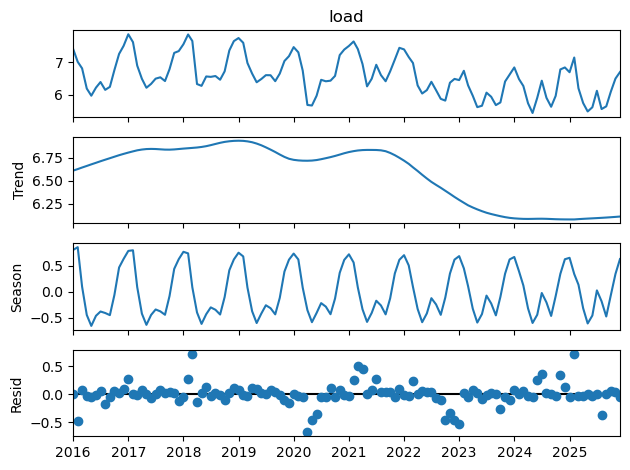

In [14]:
lm = GH['load'].resample('MS').mean(); lm.index = lm.index.tz_localize(None)
lm = (lm.loc['2016-01-01':f'{Y - 1}-12-01'] / 1000).asfreq('MS')
w = np.r_[1 / 24, np.repeat(1 / 12, 11), 1 / 24]
cma = lm.rolling(13, center=True).apply(lambda v: float(np.dot(v, w)), raw=True)
d = (lm - cma).groupby(lm.index.month).mean(); print('seasonal indices (GW)\n', (d - d.mean()).round(3))
stl = STL(lm, period=12, seasonal=13, robust=True).fit(); stl.plot(); plt.show()

## §9 Netezirea exponențială

alpha for a 10-day half-life 0.067; optimal SES alpha 0.948


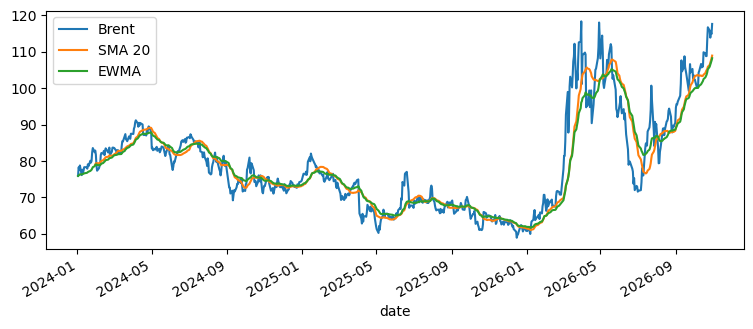

In [15]:
bs = b.loc['2024-01-01':]
alpha = 1 - 2 ** (-1 / 10)
ses = SimpleExpSmoothing(bs.values, initialization_method='estimated').fit()
print('alpha for a 10-day half-life %.3f; optimal SES alpha %.3f' % (alpha, ses.params['smoothing_level']))
pd.DataFrame({'Brent': bs, 'SMA 20': bs.rolling(20).mean(), 'EWMA': bs.ewm(alpha=alpha, adjust=False).mean()}).plot(figsize=(9, 3.5)); plt.show()

## §10 Studii de caz
### §10a 2023 ploios, 2025 secetos

In [16]:
print('hydro TWh: 2023 %.2f, 2025 %.2f, change %.1f%%' % (mix.loc[2023, 'Hydro'], mix.loc[2025, 'Hydro'],
      (mix.loc[2025, 'Hydro'] / mix.loc[2023, 'Hydro'] - 1) * 100))
dfm = pd.concat([hydro_m.rename('hydro'), P['RO'].resample('MS').mean().rename('price'),
                 TTF['ttf_eur_mwh'].rename('ttf')], axis=1).dropna()
ols = sm.OLS(dfm['price'], sm.add_constant(dfm[['hydro', 'ttf']])).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
print(ols.summary().tables[1])

hydro TWh: 2023 18.34, 2025 12.15, change -33.8%
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         44.8025     10.207      4.389      0.000      24.797      64.808
hydro        -19.5486      7.025     -2.783      0.005     -33.317      -5.780
ttf            1.8858      0.055     34.157      0.000       1.778       1.994


### §10b Șocul petrolier din iunie 2025

In [17]:
w = b.loc['2025-06-10':'2025-06-26']; print(w)
print('12->13 Jun: %+.1f%%; peak -> 24 Jun: %+.1f%%' % ((b['2025-06-13'] / b['2025-06-12'] - 1) * 100,
      (b['2025-06-24'] / b.loc['2025-06-13':'2025-06-23'].max() - 1) * 100))

date
2025-06-10    66.87
2025-06-11    69.77
2025-06-12    69.36
2025-06-13    74.23
2025-06-16    73.23
2025-06-17    76.45
2025-06-18    76.70
2025-06-20    77.01
2025-06-23    71.48
2025-06-24    67.14
2025-06-25    67.68
2025-06-26    67.73
Name: brent_usd_bbl, dtype: float64
12->13 Jun: +7.0%; peak -> 24 Jun: -12.8%


### §10c Separarea regională a prețurilor, vara 2024

RO       145.14
BG       136.47
HU       135.54
DE_LU     67.70
dtype: float64
share of July hours with equal prices: RO-BG 86.8%, RO-HU 6.3%, RO-DE 3.1%


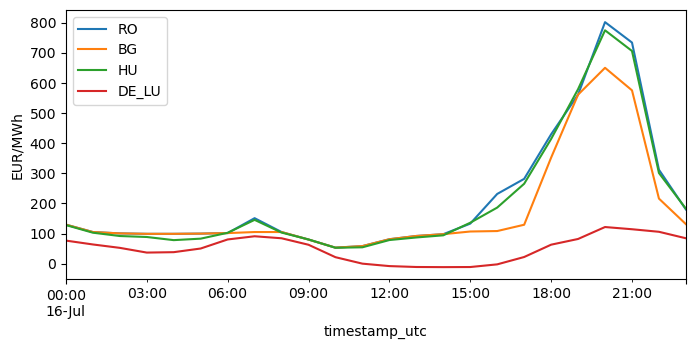

In [18]:
print(P.loc['2024-07', Z].mean().round(2))
hj = H.loc['2024-07-01':'2024-07-31', Z].dropna()
print('share of July hours with equal prices: RO-BG %.1f%%, RO-HU %.1f%%, RO-DE %.1f%%' % tuple(
      (np.abs(hj['RO'] - hj[z]) < 0.01).mean() * 100 for z in ['BG', 'HU', 'DE_LU']))
H.loc['2024-07-16', Z].plot(figsize=(8, 3.5), ylabel='EUR/MWh'); plt.show()

### §10d Prețuri negative și solar: un logit descriptiv (date realizate, nu un model de licitare)

In [19]:
nd = ((X['RO'] < 0) & X['RO'].notna()).groupby(X.index.normalize().tz_localize(None)).max().astype(float)
jj = pd.concat([nd.rename('neg'), (G['solar'] / 1000).rename('solar'), (G['wind_onshore'] / 1000).rename('wind'),
                ((G['hydro_run_of_river'] + G['hydro_water_reservoir']) / 1000).rename('hydro'),
                (G['load'] / 1000).rename('load')], axis=1).loc['2024-01-01':].dropna()
jj['residual_load'] = jj['load'] - jj['solar'] - jj['wind']   # demand left after wind and solar (GW)
jj['weekend'] = (jj.index.dayofweek >= 5).astype(float)
for yy in sorted(set(jj.index.year))[1:]:
    jj[f'y{yy}'] = (jj.index.year == yy).astype(float)
X_ = sm.add_constant(jj[['residual_load', 'hydro', 'weekend'] + [c for c in jj.columns if c.startswith('y')]])
fit = sm.Logit(jj['neg'], X_).fit(disp=0)
print(fit.summary().tables[1]); print('odds ratios:', np.exp(fit.params).round(2).to_dict())

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.0226      0.914     -0.025      0.980      -1.815       1.770
residual_load    -1.4447      0.188     -7.669      0.000      -1.814      -1.076
hydro             1.5076      0.345      4.374      0.000       0.832       2.183
weekend           2.7805      0.301      9.244      0.000       2.191       3.370
y2025             1.3373      0.336      3.982      0.000       0.679       1.996
y2026             0.5344      0.347      1.541      0.123      -0.145       1.214
odds ratios: {'const': 0.98, 'residual_load': 0.24, 'hydro': 4.52, 'weekend': 16.13, 'y2025': 3.81, 'y2026': 1.71}


### §10e Anul curent pînă acum

In [20]:
cur = P.loc[str(Y), Z].mean(); prev = P.loc[f'{Y - 1}-01-01':f'{Y - 1}-{END:%m-%d}', Z].mean()
print(pd.DataFrame({'Jan..cut-off ' + str(Y - 1): prev, 'Jan..cut-off ' + str(Y): cur, 'change %': (cur / prev - 1) * 100}).round(1))
print(pd.DataFrame({k: lfl(GRP[k]) for k in ['Nuclear', 'Hydro', 'Solar']}).T.round(2))
print('nuclear days not reported this year:', G.loc[str(Y), 'nuclear'].isna().sum(),
      '| days at 0 MW in May:', (G.loc[f'{Y}-05', 'nuclear'] < 1).sum())
hyd = (G['hydro_run_of_river'] + G['hydro_water_reservoir']).resample('MS').mean()
print(pd.DataFrame({str(Y - 1): hyd.loc[str(Y - 1)].values[:END.month], str(Y): hyd.loc[str(Y)].values}, index=range(1, END.month + 1)).round(0))
mar = b.loc[f'{Y}-03']
print('Brent, May contract within March: %.2f -> %.2f (%+.1f%%); 1 April roll: %+.1f%%' % (mar.iloc[0], mar.iloc[-1],
      (mar.iloc[-1] / mar.iloc[0] - 1) * 100, (b.loc[f'{Y}-04'].iloc[0] / mar.iloc[-1] - 1) * 100))

       Jan..cut-off 2025  Jan..cut-off 2026  change %
RO                 105.9              137.4      29.8
BG                 104.4              129.9      24.4
HU                 106.2              141.0      32.8
DE_LU               87.7              114.0      30.1


         TWh now  TWh before  change %  coverage %
Nuclear     5.10        7.42    -31.27       90.09
Hydro      10.44        9.61      8.60       99.97
Solar       4.33        2.53     71.19       99.97
nuclear days not reported this year: 29 | days at 0 MW in May: 19
      2025    2026
1   1158.0  1568.0
2   1214.0  1943.0
3   1357.0  1691.0
4   1586.0  1838.0
5   1683.0  1655.0
6   1592.0  1513.0
7   1113.0  1191.0
8   1154.0  1030.0
9   1067.0   948.0
10  1249.0   981.0
Brent, May contract within March: 77.74 -> 118.35 (+52.2%); 1 April roll: -14.5%


RO max 323.76 on 2026-10-29, min 29.63 on 2026-02-15; Brent max 118.35 on 2026-03-31


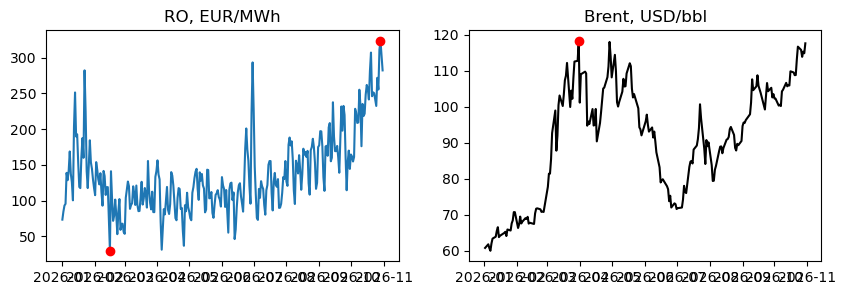

In [21]:
# extremes of the current year: RO daily base price and Brent close
ro = P.loc[str(Y), 'RO'].dropna(); bb = b.loc[str(Y)].dropna()
print('RO max %.2f on %s, min %.2f on %s; Brent max %.2f on %s' % (ro.max(), ro.idxmax().date(), ro.min(), ro.idxmin().date(),
      bb.max(), bb.idxmax().date()))
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(ro); axs[0].plot([ro.idxmax(), ro.idxmin()], [ro.max(), ro.min()], 'ro'); axs[0].set_title('RO, EUR/MWh')
axs[1].plot(bb, color='k'); axs[1].plot([bb.idxmax()], [bb.max()], 'ro'); axs[1].set_title('Brent, USD/bbl'); plt.show()

### §10f România, Bulgaria și bateriile
Ora locală (EET, București = Sofia); seara = intervalele 19:00--22:00, aprilie--septembrie.

In [22]:
XL = X.copy(); XL.index = XL.index.tz_convert('Europe/Bucharest'); wl = XL['mtu_minutes'] / 60
def wmean(z, m):
    v, ww = XL.loc[m, z], wl[m]; ok = v.notna(); return float((v[ok] * ww[ok]).sum() / ww[ok].sum())
for yy in [2024, 2025, Y]:
    base = (XL.index.year == yy) & (XL.index.month >= 4) & (XL.index.month <= 9)
    ev = base & (XL.index.hour >= 19) & (XL.index.hour <= 21)
    print(yy, 'evening RO %.1f vs BG %.1f EUR/MWh' % (wmean('RO', ev), wmean('BG', ev)))
    mid = base & (XL.index.hour >= 11) & (XL.index.hour <= 14)
    print(yy, '   midday RO %.1f vs BG %.1f EUR/MWh' % (wmean('RO', mid), wmean('BG', mid)))
bat = BGH[['battery', 'battery_consumption']].dropna(how='all')
bat.index = bat.index.tz_convert('Europe/Bucharest')
print('Bulgarian battery data start (local date):', bat.index.min().date())
print(bat.groupby(bat.index.tz_localize(None).to_period('M')).mean().round(0))

2024 evening RO 222.9 vs BG 215.8 EUR/MWh
2024    midday RO 49.3 vs BG 48.2 EUR/MWh


2025 evening RO 171.1 vs BG 169.7 EUR/MWh


2025    midday RO 29.2 vs BG 25.0 EUR/MWh
2026 evening RO 215.5 vs BG 178.0 EUR/MWh
2026    midday RO 48.1 vs BG 46.0 EUR/MWh
Bulgarian battery data start (local date): 2026-09-10
               battery  battery_consumption
timestamp_utc                              
2026-09          504.0               -622.0
2026-10          577.0               -714.0
2026-11            2.0               -306.0
